<a href="https://colab.research.google.com/github/matheus-22cmd/Data_Analyst_Portfolio_Projects/blob/master/Python_Bakery_Dataset_Exploratory_Data_Analysis_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install fg-data-profiling pandas numpy --quiet

In [ ]:
import pandas as pd
import numpy as np
import data_profiling
from data_profiling import profile_report
from google.colab import files
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so


In [ ]:
from google.colab import drive
# Monta o Google Drive no diretório padrão
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/3. Recursos/Datasets/bakery_sales_dataset.csv')

In [ ]:
df.dtypes

,0
Order_ID,object
Customer_ID,object
Customer_Age,int64
Customer_Gender,object
Customer_Segment,object
Loyalty_Member,object
Date,object
Year,int64
Month,int64
Day,int64


In [ ]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender',
       'Customer_Segment', 'Loyalty_Member', 'Date', 'Year', 'Month', 'Day',
       'Day_of_Week', 'Weekend', 'Hour', 'Time', 'Season', 'Festival',
       'Weather', 'Temperature', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price',
       'Total_Bill', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type',
       'Shelf_Life_Days', 'Storage_Type', 'Perishability', 'Store_ID',
       'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available',
       'Waste_Pct', 'Profit', 'Customer_Rating'],
      dtype='object')

In [ ]:
df.head(15)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4
5,ORD00003,CUST0389,35,Male,Young Professional,No,2023-01-01,2023,1,1,...,Room Temperature,High,ST02,2,1,1,1,50.0,14.15,5
6,ORD00004,CUST0053,23,Male,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,2,1,1,1,50.0,152.24,5
7,ORD00004,CUST0053,23,Male,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,10,9,1,1,10.0,384.90,5
8,ORD00005,CUST0454,38,Male,Family,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST01,22,14,8,7,36.4,31.38,3
9,ORD00005,CUST0454,38,Male,Family,No,2023-01-01,2023,1,1,...,Refrigerated,Medium,ST01,2,1,1,1,50.0,25.63,3


In [ ]:
df.shape

(19321, 40)

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Customer_ID,0
Customer_Age,0
Customer_Gender,0
Customer_Segment,0
Loyalty_Member,0
Date,0
Year,0
Month,0
Day,0


No campo ['Festival'] substituiremos os campos em branco por 'Regular Day'





In [ ]:
df['Festival'].fillna('Regular Day',inplace=True)

/tmp/ipykernel_1248/3767475274.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Festival'].fillna('Regular Day',inplace=True)


No campo ['Promotion_Type'] substituiremos os campos em branco por 'No Promotion Aplied'

In [ ]:
df['Promotion_Type'].fillna('No Promotion Apllied', inplace=True)


/tmp/ipykernel_1248/4067132950.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Promotion_Type'].fillna('No Promotion Apllied', inplace=True)


# Quais produtos apresentam as maiores taxas de descarte/desperdício (waste percentage) e como isso se correlaciona com o prazo de validade (shelf life), tipo de armazenamento (storage type) e dia da semana?

In [ ]:
perishability_order = ["Low", "Medium", "High", "Very High"]
df["Perishability"] = pd.Categorical(
    df["Perishability"], categories=perishability_order, ordered=True
)
dias_ordenados =['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['Day_of_Week'] = pd.Categorical(df['Day_of_Week'],categories=dias_ordenados,ordered=True)

In [ ]:
perishability_waste = (
    df.groupby("Perishability", observed=False)
    .agg(
        Total_Produced=("Units_Produced", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
        Mean_Shelf_Life=("Shelf_Life_Days", "mean"),
    )
    .reset_index()
)

perishability_waste["Weighted_Waste_Pct"] = (
    perishability_waste["Total_Unsold"]
    / perishability_waste["Total_Produced"]
) * 100

print("--- TAXA DE DESCARTE POR NÍVEL DE PERECIBILIDADE ---")
print(
    perishability_waste[
        ["Perishability", "Weighted_Waste_Pct", "Mean_Shelf_Life"]
    ]
)

--- TAXA DE DESCARTE POR NÍVEL DE PERECIBILIDADE ---
  Perishability  Weighted_Waste_Pct  Mean_Shelf_Life
0           Low           28.342017       175.087319
1        Medium           32.801338        46.000000
2          High           29.717715         4.129749
3     Very High           24.735579         2.034546


In [ ]:
pivot_storage_perish = df.pivot_table(
    index="Storage_Type",
    columns="Perishability",
    values=["Unsold_Units", "Units_Produced"],
    aggfunc="sum",
    observed=False,
)

waste_storage_perish = (
    pivot_storage_perish["Unsold_Units"]
    / pivot_storage_perish["Units_Produced"]
) * 100

print(
    "\n--- TAXA DE DESCARTE (%) CRUZADA: TIPO DE ARMAZENAMENTO VS PERECIBILIDADE ---"
)
print(waste_storage_perish)


--- TAXA DE DESCARTE (%) CRUZADA: TIPO DE ARMAZENAMENTO VS PERECIBILIDADE ---
Perishability           Low     Medium       High  Very High
Storage_Type                                                
Dry Storage       28.342017        NaN        NaN        NaN
Refrigerated            NaN  33.636865  25.997290  34.138808
Room Temperature        NaN  31.776650  31.894653  18.123163


In [ ]:
pivot_dow_perish = df.pivot_table(
    index="Day_of_Week",
    columns="Perishability",
    values=["Unsold_Units", "Units_Produced"],
    aggfunc="sum",
    observed=False,
)

waste_dow_perish = (
    pivot_dow_perish["Unsold_Units"] / pivot_dow_perish["Units_Produced"]
) * 100

print(
    "\n--- TAXA DE DESCARTE (%) CRUZADA: DIA DA SEMANA VS PERECIBILIDADE ---"
)
print(waste_dow_perish)


--- TAXA DE DESCARTE (%) CRUZADA: DIA DA SEMANA VS PERECIBILIDADE ---
Perishability        Low     Medium       High  Very High
Day_of_Week                                              
Monday         28.802412  32.178218  30.397854  24.533910
Tuesday        29.025942  33.248731  30.094467  25.632378
Wednesday      28.843609  32.967033  28.698225  25.704111
Thursday       28.048459  32.598608  31.543624  23.499090
Friday         28.240279  33.333333  30.421687  23.640593
Saturday       27.757880  32.667732  29.053064  24.581006
Sunday         28.049456  32.741935  28.902230  25.455603


In [ ]:
high_risk_products = (
    df[df["Perishability"].isin(["High", "Very High"])]
    .groupby(["Product", "Category", "Perishability", "Storage_Type"])
    .agg(
        Total_Produced=("Units_Produced", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
        Shelf_Life_Days=("Shelf_Life_Days", "first"),
    )
    .reset_index()
)

high_risk_products["Weighted_Waste_Pct"] = (
    high_risk_products["Total_Unsold"] / high_risk_products["Total_Produced"]
) * 100

top_high_risk = high_risk_products.sort_values(
    by="Weighted_Waste_Pct", ascending=False
)

print(
    "\n--- TOP 10 PRODUTOS DE ALTA PERECIBILIDADE COM MAIOR DESCARTE REAL ---"
)
print(
    top_high_risk[
        [
            "Product",
            "Category",
            "Perishability",
            "Weighted_Waste_Pct",
            "Shelf_Life_Days",
            "Storage_Type",
        ]
    ].head(10)
)


--- TOP 10 PRODUTOS DE ALTA PERECIBILIDADE COM MAIOR DESCARTE REAL ---
               Product         Category Perishability  Weighted_Waste_Pct  \
166  Butterscotch Cake            Cakes     Very High           43.575419   
694     Pineapple Cake            Cakes     Very High           42.997199   
22   Black Forest Cake            Cakes     Very High           41.526264   
214     Chocolate Cake            Cakes     Very High           39.182390   
606             Paneer  Dairy & Spreads     Very High           37.270341   
109        Brown Bread    Bread & Daily          High           35.006974   
925  Whole Wheat Bread    Bread & Daily          High           34.167386   
789           Tea Cake            Cakes          High           33.797468   
294        Cold Coffee        Beverages     Very High           33.589041   
436              Juice        Beverages          High           33.142857   

     Shelf_Life_Days      Storage_Type  
166              3.0      Refrigerated 

/tmp/ipykernel_1248/3913349599.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["Product", "Category", "Perishability", "Storage_Type"])


In [ ]:
produtos_waste = (
    df.groupby(["Product", "Category", "Storage_Type", "Shelf_Life_Days"])
    .agg(
        Total_Produced=("Units_Produced", "sum"),
        Total_Sold=("Units_Sold", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
        Mean_Waste_Pct=(
            "Waste_Pct",
            "mean",
        ),  # Média das taxas registradas por pedido
    )
    .reset_index()
)

In [ ]:
plt.show()

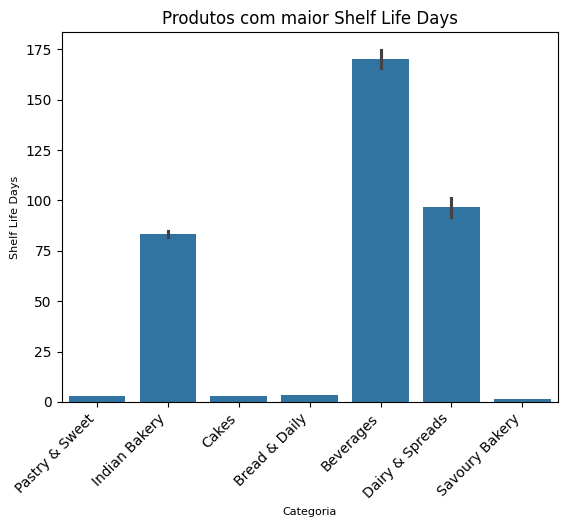

In [ ]:
sns.barplot(data=df,x='Category',y='Shelf_Life_Days' ).set(title = 'Produtos com maior Shelf Life Days')
plt.xlabel('Categoria',fontsize=8)
plt.ylabel('Shelf Life Days',fontsize=8)
plt.xticks(rotation=45, ha='right')
plt.show()
#

In [ ]:
# 1. Ajuste de Tipos Categoricos
perish_order = ["Low", "Medium", "High", "Very High"]
dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

df["Perishability"] = pd.Categorical(
    df["Perishability"], categories=perish_order, ordered=True
)
df["Day_of_Week"] = pd.Categorical(
    df["Day_of_Week"], categories=dow_order, ordered=True
)

# 2. Resumo Ponderado Global por Produto e Atributos
relatorio_produtos = (
    df.groupby(
        ["Product", "Category", "Storage_Type", "Perishability"],
        observed=False,
    )
    .agg(
        Shelf_Life_Days=("Shelf_Life_Days", "first"),
        Total_Produced=("Units_Produced", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
    )
    .reset_index()
)

relatorio_produtos["Waste_Pct_Weighted"] = (
    relatorio_produtos["Total_Unsold"] / relatorio_produtos["Total_Produced"]
) * 100
relatorio_produtos = relatorio_produtos.sort_values(
    by="Waste_Pct_Weighted", ascending=False
)

print("--- TOP 10 PRODUTOS COM MAIOR TAXA DE DESCARTE (CENÁRIO CONSOLIDADO) ---")
print(
    relatorio_produtos[
        [
            "Product",
            "Perishability",
            "Storage_Type",
            "Shelf_Life_Days",
            "Waste_Pct_Weighted",
        ]
    ].head(10)
)

# 3. Análise Multidimensional (Dia da Semana x Armazenamento x Perecibilidade)
matriz_risco = df.pivot_table(
    index=["Storage_Type", "Perishability"],
    columns="Day_of_Week",
    values=["Unsold_Units", "Units_Produced"],
    aggfunc="sum",
    observed=False,
)

taxa_matriz_risco = (
    matriz_risco["Unsold_Units"] / matriz_risco["Units_Produced"]
) * 100
print(
    "\n--- DESCARTE (%) POR ARMAZENAMENTO E PERECIBILIDADE AO LONGO DA SEMANA ---"
)
print(taxa_matriz_risco.round(2))

--- TOP 10 PRODUTOS COM MAIOR TAXA DE DESCARTE (CENÁRIO CONSOLIDADO) ---
                Product Perishability      Storage_Type  Shelf_Life_Days  \
2136      Peanut Butter           Low       Dry Storage            285.0   
1464                Jam           Low       Dry Storage            312.0   
451   Butterscotch Cake     Very High      Refrigerated              3.0   
1380              Honey           Low       Dry Storage            454.0   
2215     Pineapple Cake     Very High      Refrigerated              3.0   
115   Black Forest Cake     Very High      Refrigerated              3.0   
619      Chocolate Cake     Very High      Refrigerated              3.0   
909    Chocolate Muffin        Medium  Room Temperature              6.0   
1975             Paneer     Very High      Refrigerated              3.0   
274         Brown Bread          High  Room Temperature              4.0   

      Waste_Pct_Weighted  
2136           45.662100  
1464           43.673966  
451      

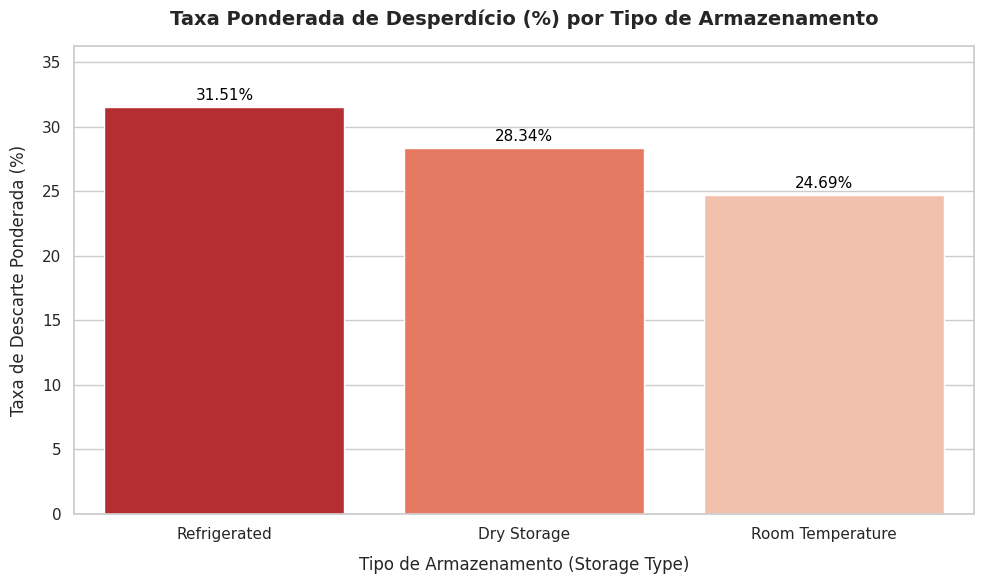

In [ ]:
# 1. Agrupar e calcular a taxa de descarte ponderada real por Storage_Type
storage_summary = (
    df.groupby("Storage_Type")
    .agg(
        Total_Produced=("Units_Produced", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
    )
    .reset_index()
)

storage_summary["Waste_Pct_Weighted"] = (
    storage_summary["Total_Unsold"] / storage_summary["Total_Produced"]
) * 100

# Ordenar do maior para o menor desperdício
storage_summary = storage_summary.sort_values(
    by="Waste_Pct_Weighted", ascending=False
)

# 2. Configuração do estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 3. Criação do gráfico de barras
ax = sns.barplot(
    data=storage_summary,
    x="Storage_Type",
    y="Waste_Pct_Weighted",
    hue="Storage_Type",
    palette="Reds_r",
    legend=False,
)

# 4. Adicionar rótulos com os valores em cima de cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.2f}%",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=11,
            color="black",
            xytext=(0, 3),
            textcoords="offset points",
        )

# 5. Personalização de títulos e eixos
plt.title(
    "Taxa Ponderada de Desperdício (%) por Tipo de Armazenamento",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Tipo de Armazenamento (Storage Type)", fontsize=12, labelpad=10)
plt.ylabel("Taxa de Descarte Ponderada (%)", fontsize=12, labelpad=10)

# Ajuste fino de limites do eixo Y para os rótulos não cortarem
plt.ylim(0, storage_summary["Waste_Pct_Weighted"].max() * 1.15)
plt.tight_layout()

plt.show()

Produtos classificados como vey high em perecividade são diretamente associados ao armazenamento refrigerado. Produtos em Room Temperature normalmente são produtos com maior resistência ao tempo

# Qual é o custo financeiro anual do desalinhamento entre unidades produzidas (units produced) e unidades vendidas (units sold) por loja?

--- CUSTO FINANCEIRO ANUAL DO DESALINHAMENTO POR LOJA ---
Store_ID  Custo_Direto_Anual_Medio  Receita_Perdida_Anual_Media  Unidades_Descartadas_Ano  Waste_Pct_Annual
    ST01                 176583.11                   302188.950                    3946.0         27.456165
    ST02                 171389.31                   292424.145                    3675.0         28.256189
    ST03                 165401.05                   282848.340                    3727.0         27.806170


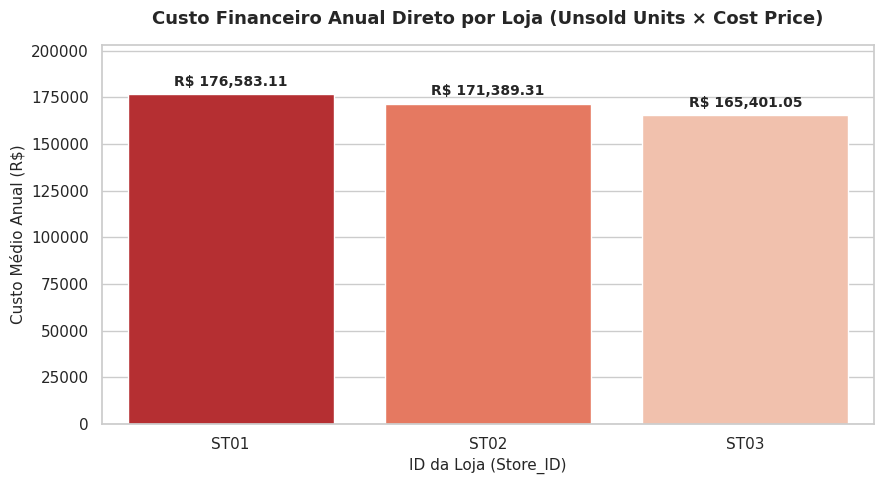

In [ ]:
# ---------------------------------------------------------
# Step 1: Cálculo Financeiro no Nível da Transação
# ---------------------------------------------------------
# Recalcular as unidades não vendidas para garantia
df["Unsold_Units"] = df["Units_Produced"] - df["Units_Sold"]

# Custo direto da produção descartada (Cost Price)
df["Waste_Cost_Financial"] = df["Unsold_Units"] * df["Cost_Price"]

# Receita perdida potencial (Selling Price)
df["Waste_Revenue_Lost"] = df["Unsold_Units"] * df["Selling_Price"]

# ---------------------------------------------------------
# Step 2: Agrupamento por Loja e Ano (Store_ID x Year)
# ---------------------------------------------------------
lojas_ano = (
    df.groupby(["Store_ID", "Year"])
    .agg(
        Total_Produced=("Units_Produced", "sum"),
        Total_Sold=("Units_Sold", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
        Custo_Desperdicio_Ano=("Waste_Cost_Financial", "sum"),
        Receita_Perdida_Ano=("Waste_Revenue_Lost", "sum"),
    )
    .reset_index()
)

# ---------------------------------------------------------
# Step 3: Consolidação da Média Anual por Loja
# ---------------------------------------------------------
custo_anual_loja = (
    lojas_ano.groupby("Store_ID")
    .agg(
        Custo_Direto_Anual_Medio=("Custo_Desperdicio_Ano", "mean"),
        Receita_Perdida_Anual_Media=("Receita_Perdida_Ano", "mean"),
        Unidades_Descartadas_Ano=("Total_Unsold", "mean"),
        Unidades_Produzidas_Ano=("Total_Produced", "mean"),
    )
    .reset_index()
)

# Taxa anual de descarte ponderada por volume (%)
custo_anual_loja["Waste_Pct_Annual"] = (
    custo_anual_loja["Unidades_Descartadas_Ano"]
    / custo_anual_loja["Unidades_Produzidas_Ano"]
) * 100

# Ordenar pelas lojas de maior prejuízo financeiro
custo_anual_loja = custo_anual_loja.sort_values(
    by="Custo_Direto_Anual_Medio", ascending=False
)

print("--- CUSTO FINANCEIRO ANUAL DO DESALINHAMENTO POR LOJA ---")
print(
    custo_anual_loja[
        [
            "Store_ID",
            "Custo_Direto_Anual_Medio",
            "Receita_Perdida_Anual_Media",
            "Unidades_Descartadas_Ano",
            "Waste_Pct_Annual",
        ]
    ].to_string(index=False)
)

# ---------------------------------------------------------
# Step 4: Gráfico do Custo Anual por Loja
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=custo_anual_loja,
    x="Store_ID",
    y="Custo_Direto_Anual_Medio",
    hue="Store_ID",
    palette="Reds_r",
    legend=False,
)

# Adicionar valores monetários sobre cada barra
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(
            f"R$ {val:,.2f}",
            (p.get_x() + p.get_width() / 2.0, val),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 4),
            textcoords="offset points",
        )

plt.title(
    "Custo Financeiro Anual Direto por Loja (Unsold Units × Cost Price)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("ID da Loja (Store_ID)", fontsize=11)
plt.ylabel("Custo Médio Anual (R$)", fontsize=11)
plt.ylim(0, custo_anual_loja["Custo_Direto_Anual_Medio"].max() * 1.15)
plt.tight_layout()
plt.show()

Podemos perceber que a Loja ST01 apresentada o maior custo financeiro quando calculamos o desalinhamento entre produção e vendas

=== LOJA COM MAIOR PROFIT ===
Loja Campeã: ST01
Profit Médio Anual: R$ 199,739.37
Profit Total (2 anos): R$ 399,478.74
Eficiência de Lucro (Retenção): 53.08%

--- RANKING COMPLETO DE LOJAS ---
Store_ID  Profit_Anual_Medio  Custo_Desperdicio_Anual_Medio  Profit_Potencial_Medio  Retencao_Lucro_%
    ST01          199739.370                      176583.11              376322.480         53.076651
    ST02          189073.025                      171389.31              360462.335         52.452921
    ST03          183056.380                      165401.05              348457.430         52.533355


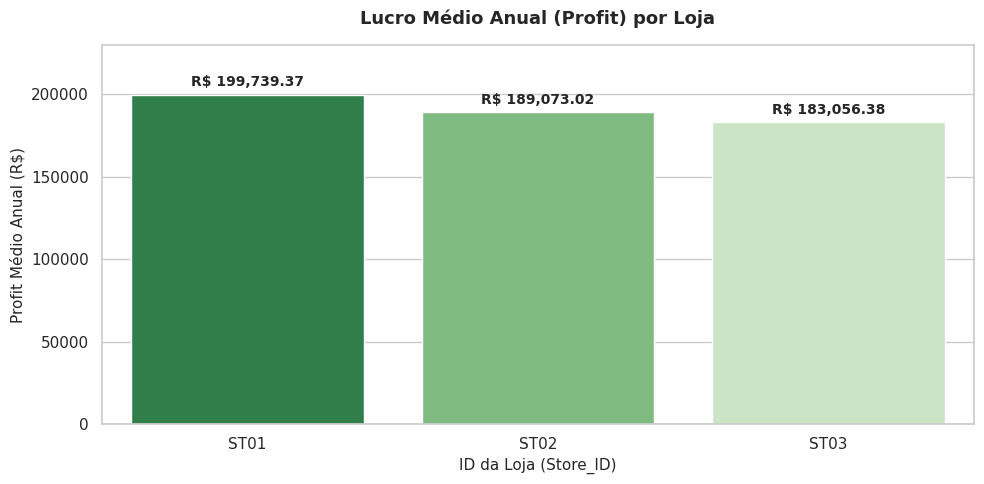

In [ ]:
# ---------------------------------------------------------
# Step 1: Agrupamento Financeiro por Loja e Ano
# ---------------------------------------------------------
# Agrupa por loja e ano para extrair o lucro e o descarte
profit_loja_ano = (
    df.groupby(["Store_ID", "Year"])
    .agg(
        Profit_Ano=("Profit", "sum"),
        Revenue_Ano=("Total_Bill", "sum"),
        Waste_Cost_Ano=(
            "Waste_Cost_Financial",
            "sum",
        ),  # Unsold_Units * Cost_Price
        Units_Produced_Ano=("Units_Produced", "sum"),
        Units_Sold_Ano=("Units_Sold", "sum"),
    )
    .reset_index()
)

# ---------------------------------------------------------
# Step 2: Consolidação da Média Anual por Loja
# ---------------------------------------------------------
resumo_lojas = (
    profit_loja_ano.groupby("Store_ID")
    .agg(
        Profit_Anual_Medio=("Profit_Ano", "mean"),
        Profit_Total_Acumulado=(
            "Profit_Ano",
            "sum",
        ),  # Total dos 2 anos de operação
        Receita_Anual_Media=("Revenue_Ano", "mean"),
        Custo_Desperdicio_Anual_Medio=("Waste_Cost_Ano", "mean"),
    )
    .reset_index()
)

# Lucro Potencial Se Não Houvesse Desperdício
resumo_lojas["Profit_Potencial_Medio"] = (
    resumo_lojas["Profit_Anual_Medio"]
    + resumo_lojas["Custo_Desperdicio_Anual_Medio"]
)

# % do Lucro Retido (Eficiência de Processo)
resumo_lojas["Retencao_Lucro_%"] = (
    resumo_lojas["Profit_Anual_Medio"] / resumo_lojas["Profit_Potencial_Medio"]
) * 100

# Ordena pela loja de maior Profit
resumo_lojas = resumo_lojas.sort_values(
    by="Profit_Anual_Medio", ascending=False
)

loja_campea = resumo_lojas.iloc[0]

print("=== LOJA COM MAIOR PROFIT ===")
print(f"Loja Campeã: {loja_campea['Store_ID']}")
print(f"Profit Médio Anual: R$ {loja_campea['Profit_Anual_Medio']:,.2f}")
print(f"Profit Total (2 anos): R$ {loja_campea['Profit_Total_Acumulado']:,.2f}")
print(
    f"Eficiência de Lucro (Retenção): {loja_campea['Retencao_Lucro_%']:.2f}%\n"
)

print("--- RANKING COMPLETO DE LOJAS ---")
print(
    resumo_lojas[
        [
            "Store_ID",
            "Profit_Anual_Medio",
            "Custo_Desperdicio_Anual_Medio",
            "Profit_Potencial_Medio",
            "Retencao_Lucro_%",
        ]
    ].to_string(index=False)
)

# ---------------------------------------------------------
# Step 3: Visualização - Lucro Real vs. Custo do Desperdício
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Gráfico de barras comparando o Profit Anual por Loja
ax = sns.barplot(
    data=resumo_lojas,
    x="Store_ID",
    y="Profit_Anual_Medio",
    hue="Store_ID",
    palette="Greens_r",
    legend=False,
)

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(
            f"R$ {val:,.2f}",
            (p.get_x() + p.get_width() / 2.0, val),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 4),
            textcoords="offset points",
        )

plt.title(
    "Lucro Médio Anual (Profit) por Loja",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("ID da Loja (Store_ID)", fontsize=11)
plt.ylabel("Profit Médio Anual (R$)", fontsize=11)
plt.ylim(0, resumo_lojas["Profit_Anual_Medio"].max() * 1.15)
plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# Step 1: Preparação de Variáveis e Categorias
# ---------------------------------------------------------
perish_order = [ "Low", "Medium", "High", "Very High"]
dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

df["Perishability"] = pd.Categorical(
    df["Perishability"], categories=perish_order, ordered=True
)
df["Day_of_Week"] = pd.Categorical(
    df["Day_of_Week"], categories=dow_order, ordered=True
)

# Métricas no nível da transação
df["Unsold_Units"] = df["Units_Produced"] - df["Units_Sold"]
df["Waste_Cost_Financial"] = (
    df["Unsold_Units"] * df["Cost_Price"]
)  # Custo direto da perda

# ---------------------------------------------------------
# Step 2: Ranking de Produtos (Desperdício Ponderado & Custo Direto)
# ---------------------------------------------------------
ranking_produtos = (
    df.groupby(
        ["Product", "Category", "Storage_Type", "Perishability"],
        observed=False,
    )
    .agg(
        Shelf_Life_Days=("Shelf_Life_Days", "first"),
        Total_Produced=("Units_Produced", "sum"),
        Total_Unsold=("Unsold_Units", "sum"),
        Total_Waste_Cost=("Waste_Cost_Financial", "sum"),
    )
    .reset_index()
)

ranking_produtos["Waste_Pct_Weighted"] = (
    ranking_produtos["Total_Unsold"] / ranking_produtos["Total_Produced"]
) * 100
ranking_produtos = ranking_produtos.sort_values(
    by="Total_Waste_Cost", ascending=False
)

print("=== TOP 10 PRODUTOS COM MAIOR IMPACTO FINANCEIRO DE DESPERDÍCIO ===")
print(
    ranking_produtos[
        [
            "Product",
            "Storage_Type",
            "Perishability",
            "Shelf_Life_Days",
            "Waste_Pct_Weighted",
            "Total_Waste_Cost",
        ]
    ]
    .head(10)
    .to_string(index=False)
)

# ---------------------------------------------------------
# Step 3: Análise Multidimensional (Armazenamento x Perecibilidade)
# ---------------------------------------------------------
matriz_perda_financeira = df.pivot_table(
    index="Storage_Type",
    columns="Perishability",
    values="Waste_Cost_Financial",
    aggfunc="sum",
    observed=False,
)

print("\n=== CUSTO TOTAL DE DESPERDÍCIO (R$) : ARMAZENAMENTO VS PERECIBILIDADE ===")
print(matriz_perda_financeira.round(2))

# ---------------------------------------------------------
# Step 4: Consolidação por Loja (Lucro Neto vs. Custo do Desperdício)
# ---------------------------------------------------------
lojas_ano = (
    df.groupby(["Store_ID", "Year"])
    .agg(
        Profit_Ano=("Profit", "sum"),
        Waste_Cost_Ano=("Waste_Cost_Financial", "sum"),
        Units_Produced_Ano=("Units_Produced", "sum"),
        Units_Unsold_Ano=("Unsold_Units", "sum"),
    )
    .reset_index()
)

resumo_lojas = (
    lojas_ano.groupby("Store_ID")
    .agg(
        Profit_Anual_Medio=("Profit_Ano", "mean"),
        Profit_Total_2Anos=("Profit_Ano", "sum"),
        Custo_Desperdicio_Anual_Medio=("Waste_Cost_Ano", "mean"),
        Waste_Cost_Total_2Anos=("Waste_Cost_Ano", "sum"),
        Unidades_Descartadas_Ano=("Units_Unsold_Ano", "mean"),
        Unidades_Produzidas_Ano=("Units_Produced_Ano", "mean"),
    )
    .reset_index()
)

# Cálculos complementares de performance financeira
resumo_lojas["Waste_Pct_Annual_Weighted"] = (
    resumo_lojas["Unidades_Descartadas_Ano"]
    / resumo_lojas["Unidades_Produzidas_Ano"]
) * 100
resumo_lojas["Profit_Potencial_Anual"] = (
    resumo_lojas["Profit_Anual_Medio"]
    + resumo_lojas["Custo_Desperdicio_Anual_Medio"]
)
resumo_lojas["Retencao_Lucro_%"] = (
    resumo_lojas["Profit_Anual_Medio"] / resumo_lojas["Profit_Potencial_Anual"]
) * 100

resumo_lojas = resumo_lojas.sort_values(
    by="Profit_Anual_Medio", ascending=False
)

print("\n=== PERFORMANCE FINANCEIRA E DESPERDÍCIO POR LOJA ===")
print(
    resumo_lojas[
        [
            "Store_ID",
            "Profit_Anual_Medio",
            "Custo_Desperdicio_Anual_Medio",
            "Waste_Pct_Annual_Weighted",
            "Retencao_Lucro_%",
        ]
    ].to_string(index=False)
)

loja_lider = resumo_lojas.iloc[0]
print(f"\n--- DIAGNÓSTICO DA LOJA LÍDER ---")
print(f"Maior Profit Médio Anual: {loja_lider['Store_ID']}")
print(f"Lucro Anual Real: R$ {loja_lider['Profit_Anual_Medio']:,.2f}")
print(
    f"Perda Anual em Custo de Produção (Cost Price): R$ {loja_lider['Custo_Desperdicio_Anual_Medio']:,.2f}"
)
print(f"Taxa de Retenção de Lucro: {loja_lider['Retencao_Lucro_%']:.2f}%")

=== TOP 10 PRODUTOS COM MAIOR IMPACTO FINANCEIRO DE DESPERDÍCIO ===
          Product     Storage_Type Perishability  Shelf_Life_Days  Waste_Pct_Weighted  Total_Waste_Cost
   Chocolate Cake     Refrigerated     Very High              3.0           39.182390         157321.90
Black Forest Cake     Refrigerated     Very High              3.0           41.526264         113310.56
Butterscotch Cake     Refrigerated     Very High              3.0           43.575419          77713.67
   Pineapple Cake     Refrigerated     Very High              3.0           42.997199          71115.35
          Cookies      Dry Storage           Low            109.0           24.452084          68347.80
         Tea Cake Room Temperature          High              5.0           33.797468          44028.41
Chocolate Cookies      Dry Storage           Low            111.0           26.592179          32246.36
        Nankhatai      Dry Storage           Low             23.0           24.622506          30228

In [ ]:
# ---------------------------------------------------------
# Step 1: Tratamento de Categorias Ordinais
# ---------------------------------------------------------
perish_order = ["Low", "Medium", "High", "Very High"]
df["Perishability"] = pd.Categorical(
    df["Perishability"], categories=perish_order, ordered=True
)

# Cálculo do custo financeiro da perda no nível da transação
df["Unsold_Units"] = df["Units_Produced"] - df["Units_Sold"]
df["Waste_Cost_Financial"] = df["Unsold_Units"] * df["Cost_Price"]

# ---------------------------------------------------------
# Step 2: Custo do Desalinhamento por Loja e Perecibilidade (Cenário 2)
# ---------------------------------------------------------
perda_perecibilidade_loja = df.pivot_table(
    index="Store_ID",
    columns="Perishability",
    values="Waste_Cost_Financial",
    aggfunc="sum",
    observed=False,
)

# Dividir por 2 para obter a média anualizada por nível de risco
perda_perecibilidade_loja_anual = perda_perecibilidade_loja / 2
print("=== CUSTO ANUAL DO DESCARTE (R$) POR LOJA E NÍVEL DE PERECIBILIDADE ===")
print(perda_perecibilidade_loja_anual.round(2))

# ---------------------------------------------------------
# Step 3: Consolidação do Desalinhamento Anual e Profit por Loja
# ---------------------------------------------------------
lojas_ano = (
    df.groupby(["Store_ID", "Year"])
    .agg(
        Profit_Ano=("Profit", "sum"),
        Waste_Cost_Ano=("Waste_Cost_Financial", "sum"),
        Units_Produced_Ano=("Units_Produced", "sum"),
        Units_Unsold_Ano=("Unsold_Units", "sum"),
    )
    .reset_index()
)

resumo_lojas = (
    lojas_ano.groupby("Store_ID")
    .agg(
        Profit_Anual_Medio=("Profit_Ano", "mean"),
        Profit_Total_2Anos=("Profit_Ano", "sum"),
        Custo_Desalinhamento_Anual=("Waste_Cost_Ano", "mean"),
        Unidades_Descartadas_Ano=("Units_Unsold_Ano", "mean"),
        Unidades_Produzidas_Ano=("Units_Produced_Ano", "mean"),
    )
    .reset_index()
)

# Cálculo de Taxa Ponderada e Retenção
resumo_lojas["Waste_Pct_Weighted"] = (
    resumo_lojas["Unidades_Descartadas_Ano"]
    / resumo_lojas["Unidades_Produzidas_Ano"]
) * 100
resumo_lojas["Profit_Potencial"] = (
    resumo_lojas["Profit_Anual_Medio"]
    + resumo_lojas["Custo_Desalinhamento_Anual"]
)
resumo_lojas["Retencao_Lucro_%"] = (
    resumo_lojas["Profit_Anual_Medio"] / resumo_lojas["Profit_Potencial"]
) * 100

# Ordenação pelo maior Profit Médio Anual
resumo_lojas = resumo_lojas.sort_values(
    by="Profit_Anual_Medio", ascending=False
)

print("\n=== CONSOLIDAÇÃO FINANCEIRA ANUAL POR FRANQUIA ===")
print(
    resumo_lojas[
        [
            "Store_ID",
            "Profit_Anual_Medio",
            "Custo_Desalinhamento_Anual",
            "Waste_Pct_Weighted",
            "Retencao_Lucro_%",
        ]
    ].to_string(index=False)
)

# ---------------------------------------------------------
# Step 4: Identificação da Loja Campeã
# ---------------------------------------------------------
loja_campea = resumo_lojas.iloc[0]

print("\n==================================================")
print(f"RESULTADO: LOJA COM MAIOR PROFIT -> {loja_campea['Store_ID']}")
print(f"• Profit Médio Anual: R$ {loja_campea['Profit_Anual_Medio']:,.2f}")
print(f"• Profit Total (2 anos): R$ {loja_campea['Profit_Total_2Anos']:,.2f}")
print(
    f"• Custo do Desalinhamento (Perda em Cost Price/Ano): R$ {loja_campea['Custo_Desalinhamento_Anual']:,.2f}"
)
print(
    f"• Taxa de Retenção do Lucro Potencial: {loja_campea['Retencao_Lucro_%']:.2f}%"
)
print("==================================================")

=== CUSTO ANUAL DO DESCARTE (R$) POR LOJA E NÍVEL DE PERECIBILIDADE ===
Perishability       Low    Medium      High  Very High
Store_ID                                              
ST01           47587.26  12912.52  27545.82   88537.52
ST02           45743.57  12464.36  25004.88   88176.49
ST03           43862.96  12542.68  25601.55   83393.87

=== CONSOLIDAÇÃO FINANCEIRA ANUAL POR FRANQUIA ===
Store_ID  Profit_Anual_Medio  Custo_Desalinhamento_Anual  Waste_Pct_Weighted  Retencao_Lucro_%
    ST01          199739.370                   176583.11           27.456165         53.076651
    ST02          189073.025                   171389.31           28.256189         52.452921
    ST03          183056.380                   165401.05           27.806170         52.533355

RESULTADO: LOJA COM MAIOR PROFIT -> ST01
• Profit Médio Anual: R$ 199,739.37
• Profit Total (2 anos): R$ 399,478.74
• Custo do Desalinhamento (Perda em Cost Price/Ano): R$ 176,583.11
• Taxa de Retenção do Lucro Potencial

Pergunta: Membros do programa de fidelidade (loyalty membership) possuem um Lifetime Value (LTV) e ticket médio (total bill) significativamente maiores do que clientes não cadastrados?

In [ ]:
from scipy import stats

In [ ]:
# ---------------------------------------------------------
# Step 1: Análise do Ticket Médio por Transação (Total_Bill)
# ---------------------------------------------------------
ticket_medio = (
    df.groupby("Loyalty_Member")
    .agg(
        Total_Transacoes=("Order_ID", "count"),
        Ticket_Medio=("Total_Bill", "mean"),
        Ticket_Mediano=("Total_Bill", "median"),
        Desvio_Padrao=("Total_Bill", "std"),
    )
    .reset_index()
)

print("=== TICKET MÉDIO POR TRANSAÇÃO (TOTAL BILL) ===")
print(ticket_medio.to_string(index=False))

# ---------------------------------------------------------
# Step 2: Cálculo do Lifetime Value (LTV) por Cliente
# ---------------------------------------------------------
# Agrupamos por cliente único para calcular o LTV real acumulado nos 2 anos
ltv_clientes = (
    df.groupby(["Customer_ID", "Loyalty_Member"])
    .agg(
        LTV=("Total_Bill", "sum"),
        Frequencia_Compras=("Order_ID", "count"),
        Ticket_Medio_Cliente=("Total_Bill", "mean"),
    )
    .reset_index()
)

ltv_resumo = (
    ltv_clientes.groupby("Loyalty_Member")
    .agg(
        Total_Clientes=("Customer_ID", "count"),
        LTV_Medio=("LTV", "mean"),
        LTV_Mediano=("LTV", "median"),
        Frequencia_Media=("Frequencia_Compras", "mean"),
    )
    .reset_index()
)

print("\n=== LIFETIME VALUE (LTV) E FREQUÊNCIA POR CLIENTE ===")
print(ltv_resumo.to_string(index=False))

# ---------------------------------------------------------
# Step 3: Teste de Significância Estatística (T-Test)
# ---------------------------------------------------------
# Separar os grupos
membros_bill = df[df["Loyalty_Member"] == True]["Total_Bill"]
nao_membros_bill = df[df["Loyalty_Member"] == False]["Total_Bill"]

membros_ltv = ltv_clientes[ltv_clientes["Loyalty_Member"] == True]["LTV"]
nao_membros_ltv = ltv_clientes[ltv_clientes["Loyalty_Member"] == False]["LTV"]

# Teste t para Ticket Médio
t_stat_bill, p_val_bill = stats.ttest_ind(
    membros_bill, nao_membros_bill, equal_var=False
)

# Teste t para LTV
t_stat_ltv, p_val_ltv = stats.ttest_ind(
    membros_ltv, nao_membros_ltv, equal_var=False
)

print("\n=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (p-value < 0.05) ===")
print(
    f"Ticket Médio - Estatística t: {t_stat_bill:.4f} | p-value: {p_val_bill:.4e}"
)
if p_val_bill < 0.05:
    print(
        "-> A diferença no TICKET MÉDIO entre membros e não membros É estatisticamente significativa."
    )
else:
    print(
        "-> A diferença no TICKET MÉDIO NÃO é estatisticamente significativa."
    )

print(f"\nLTV - Estatística t: {t_stat_ltv:.4f} | p-value: {p_val_ltv:.4e}")
if p_val_ltv < 0.05:
    print(
        "-> A diferença no LTV entre membros e não membros É estatisticamente significativa."
    )
else:
    print("-> A diferença no LTV NÃO é estatisticamente significativa.")

=== TICKET MÉDIO POR TRANSAÇÃO (TOTAL BILL) ===
Loyalty_Member  Total_Transacoes  Ticket_Medio  Ticket_Mediano  Desvio_Padrao
            No             11205    138.882548           83.14     154.844828
           Yes              8116    139.801269           82.48     161.735709

=== LIFETIME VALUE (LTV) E FREQUÊNCIA POR CLIENTE ===
Loyalty_Member  Total_Clientes   LTV_Medio  LTV_Mediano  Frequencia_Media
            No             294 5293.125680     4950.430         38.112245
           Yes             206 5507.898544     5267.165         39.398058

=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (p-value < 0.05) ===
Ticket Médio - Estatística t: nan | p-value: nan
-> A diferença no TICKET MÉDIO NÃO é estatisticamente significativa.

LTV - Estatística t: nan | p-value: nan
-> A diferença no LTV NÃO é estatisticamente significativa.


/usr/local/lib/python3.13/dist-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


Em resumo o programa de fidelidade não apresenta resultados significativos no faturamento total

Pergunta: Como o perfil demográfico (idade, gênero, segmento) varia de acordo com o horário da compra (hour) e dia da semana (day of the week)?

In [ ]:
# ---------------------------------------------------------
# Step 1: Ordenação Lógica dos Dias da Semana e Faixas Horárias
# ---------------------------------------------------------
# Mapear Turnos Operacionais da Padaria baseados na coluna Hour
condicoes_turno = [
    (df["Hour"] >= 6) & (df["Hour"] < 11),  # Café da Manhã
    (df["Hour"] >= 11) & (df["Hour"] < 14),  # Almoço / Brunch
    (df["Hour"] >= 14) & (df["Hour"] < 18),  # Lanche da Tarde
    (df["Hour"] >= 18) & (df["Hour"] <= 23),  # Noite / Happy Hour
]

nomes_turnos = [
    "1. Café da Manhã (06h-10h)",
    "2. Almoço (11h-13h)",
    "3. Lanche Tarde (14h-17h)",
    "4. Noite (18h-23h)",
]

df["Turno_Operacional"] = pd.Series(
    pd.Categorical(
        pd.Series(
            pd.np.select(condicoes_turno, nomes_turnos, default="Madrugada")
            if hasattr(pd, "np")
            else [
                nomes_turnos[0]
                if 6 <= h < 11
                else nomes_turnos[1]
                if 11 <= h < 14
                else nomes_turnos[2]
                if 14 <= h < 18
                else nomes_turnos[3]
                if 18 <= h <= 23
                else "Madrugada"
                for h in df["Hour"]
            ]
        )
    )
)

# ---------------------------------------------------------
# Step 2: Perfil por Segmento de Cliente vs. Dia da Semana e Hora
# ---------------------------------------------------------
segmento_dow_hour = (
    df.groupby(["Day_of_Week", "Turno", "Customer_Segment"], observed=False)
    .agg(
        Total_Transacoes=("Order_ID", "count"),
        Faturamento_Total=("Total_Bill", "sum"),
        Ticket_Medio=("Total_Bill", "mean"),
    )
    .reset_index()
)

print("=== DISTRIBUIÇÃO DE FATURAMENTO POR SEGMENTO E TURNO ===")
print(
    segmento_dow_hour.pivot_table(
        index="Turno",
        columns="Customer_Segment",
        values="Faturamento_Total",
        aggfunc="sum",
        observed=False,
    ).round(2)
)

# ---------------------------------------------------------
# Step 3: Idade Média por Horário e Dia da Semana (Matriz Heatmap)
# ---------------------------------------------------------
pivot_idade = df.pivot_table(
    index="Hour",
    columns="Day_of_Week",
    values="Customer_Age",
    aggfunc="mean",
    observed=False,
)

print("\n=== IDADE MÉDIA DOS CLIENTES POR HORA E DIA DA SEMANA ===")
print(pivot_idade.round(1))

# ---------------------------------------------------------
# Step 4: Proporção de Gênero por Horário do Dia
# ---------------------------------------------------------
genero_hora = (
    df.groupby(["Hour", "Customer_Gender"], observed=False)
    .agg(Total=("Order_ID", "count"))
    .reset_index()
)

pivot_genero = genero_hora.pivot_table(
    index="Hour",
    columns="Customer_Gender",
    values="Total",
    aggfunc="sum",
    fill_value=0,
)

# Porcentagem de cada gênero por hora
pivot_genero_pct = pivot_genero.div(pivot_genero.sum(axis=1), axis=0) * 100

print("\n=== PROPORÇÃO DE GÊNERO (%) POR HORÁRIO DAS COMPRAS ===")
print(pivot_genero_pct.round(1))

# ---------------------------------------------------------
# Step 5: Visualizações Gráficas
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Visualização 1: Heatmap de Idade Média por Hora e Dia da Semana
sns.heatmap(
    pivot_idade,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    ax=axes[0],
    cbar_kws={"label": "Idade Média"},
)
axes[0].set_title(
    "Idade Média dos Clientes por Horário e Dia da Semana",
    fontsize=13,
    fontweight="bold",
)
axes[0].set_xlabel("Dia da Semana")
axes[0].set_ylabel("Hora do Dia")

# Visualização 2: Volume de Vendas por Segmento e Turno
sns.barplot(
    data=df,
    x="Turno",
    y="Total_Bill",
    hue="Customer_Segment",
    estimator=sum,
    errorbar=None,
    ax=axes[1],
    palette="Blues_r",
)
axes[1].set_title(
    "Faturamento Total por Segmento de Cliente em Cada Turno",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Turno")
axes[1].set_ylabel("Faturamento Total (R$)")

plt.tight_layout()
plt.show()

KeyError: 'Turno'

=== VOLUME DE UNIDADES VENDIDAS: CATEGORIA VS ESTAÇÃO DO ANO ===
Season           Autumn  Monsoon  Summer  Winter
Category                                        
Beverages           874     2340    1962    1696
Bread & Daily      1729     3158    2634    2412
Cakes               759     1002     743     910
Dairy & Spreads    1536     2932    2055    1606
Indian Bakery      2962     5195    3354    4469
Pastry & Sweet     1503     3016    2072    2278
Savoury Bakery      665     2573     951    1481

=== SHARE DE VENDAS (%) POR CATEGORIA EM CADA CONDICIONAL DE CLIMA ===
Category  Beverages  Bread & Daily  Cakes  Dairy & Spreads  Indian Bakery  \
Weather                                                                     
Clear         11.34          17.71   5.80            13.89          28.38   
Cold          11.64          15.97   6.26            10.99          31.25   
Foggy         10.49          16.07   7.26            10.86          30.13   
Hot           14.49          18.37   

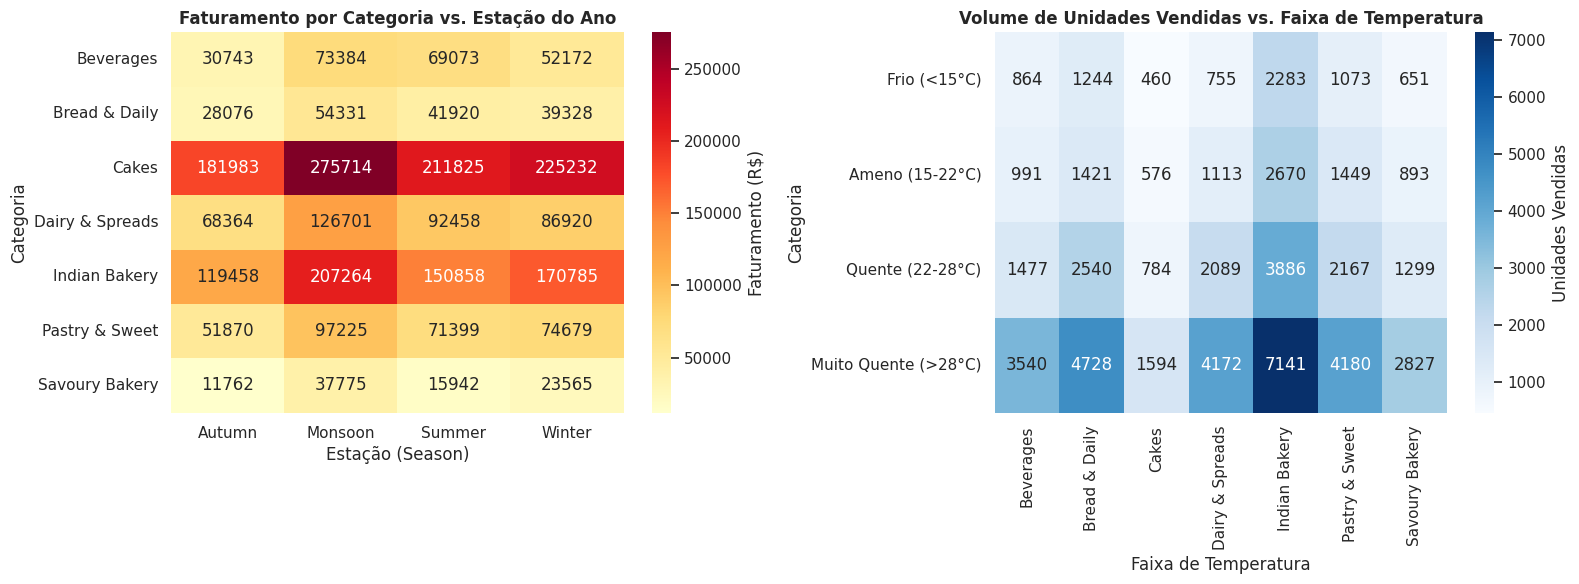

In [ ]:
# ---------------------------------------------------------
# Step 1: Preparação de Faixas de Temperatura
# ---------------------------------------------------------
# Categorizar a temperatura contínua em faixas operacionais
bins_temp = [-float("inf"), 15, 22, 28, float("inf")]
labels_temp = ["Frio (<15°C)", "Ameno (15-22°C)", "Quente (22-28°C)", "Muito Quente (>28°C)"]

df["Temp_Range"] = pd.cut(
    df["Temperature"], bins=bins_temp, labels=labels_temp, right=False
)

# ---------------------------------------------------------
# Step 2: Faturamento e Volume por Categoria vs. Estação (Season)
# ---------------------------------------------------------
vendas_estacao = (
    df.groupby(["Season", "Category"], observed=False)
    .agg(
        Total_Unidades=("Units_Sold", "sum"),
        Faturamento_Total=("Total_Bill", "sum"),
        Ticket_Medio=("Total_Bill", "mean"),
    )
    .reset_index()
)

# Matriz Cruzada: Estação x Categoria (Volume Vendido)
pivot_estacao = vendas_estacao.pivot_table(
    index="Category",
    columns="Season",
    values="Total_Unidades",
    aggfunc="sum",
    fill_value=0,
)

print("=== VOLUME DE UNIDADES VENDIDAS: CATEGORIA VS ESTAÇÃO DO ANO ===")
print(pivot_estacao)

# ---------------------------------------------------------
# Step 3: Impacto do Clima (Weather) nas Categorias
# ---------------------------------------------------------
vendas_clima = (
    df.groupby(["Weather", "Category"], observed=False)
    .agg(
        Total_Unidades=("Units_Sold", "sum"),
        Faturamento_Total=("Total_Bill", "sum"),
    )
    .reset_index()
)

# Participação relativa (%) de cada categoria dentro de cada tipo de clima
pivot_clima_pct = vendas_clima.pivot_table(
    index="Weather",
    columns="Category",
    values="Total_Unidades",
    aggfunc="sum",
    fill_value=0,
)
pivot_clima_pct = pivot_clima_pct.div(pivot_clima_pct.sum(axis=1), axis=0) * 100

print("\n=== SHARE DE VENDAS (%) POR CATEGORIA EM CADA CONDICIONAL DE CLIMA ===")
print(pivot_clima_pct.round(2))

# ---------------------------------------------------------
# Step 4: Matriz Cruzada - Faixa de Temperatura vs. Categoria
# ---------------------------------------------------------
pivot_temp = df.pivot_table(
    index="Temp_Range",
    columns="Category",
    values="Units_Sold",
    aggfunc="sum",
    observed=False,
    fill_value=0,
)

print("\n=== VOLUME DE VENDAS POR FAIXA DE TEMPERATURA ===")
print(pivot_temp)

# ---------------------------------------------------------
# Step 5: Visualização Gráfica (Heatmap de Relevância)
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap 1: Estação do Ano vs Categoria (Faturamento)
pivot_estacao_fat = vendas_estacao.pivot_table(
    index="Category",
    columns="Season",
    values="Faturamento_Total",
    aggfunc="sum",
    fill_value=0,
)
sns.heatmap(
    pivot_estacao_fat,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    ax=axes[0],
    cbar_kws={"label": "Faturamento (R$)"},
)
axes[0].set_title(
    "Faturamento por Categoria vs. Estação do Ano",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Estação (Season)")
axes[0].set_ylabel("Categoria")

# Heatmap 2: Faixa de Temperatura vs Categoria (Volume)
sns.heatmap(
    pivot_temp,
    cmap="Blues",
    annot=True,
    fmt="d",
    ax=axes[1],
    cbar_kws={"label": "Unidades Vendidas"},
)
axes[1].set_title(
    "Volume de Unidades Vendidas vs. Faixa de Temperatura",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Faixa de Temperatura")
axes[1].set_ylabel("Categoria")

plt.tight_layout()
plt.show()

=== COMPARATIVO FINANCEIRO: FESTIVAL VS. DIAS NORMAIS ===
        Festival  Total_Pedidos  Volume_Vendido  Volume_Produzido  Faturamento_Total  Profit_Total  Custo_Desperdicio_Total  Ticket_Medio  Profit_Medio_Pedido  Desconto_Medio_Pct  Margem_Lucro_Media_Pct  Margem_Global_Pct  Waste_Pct_Weighted
       Christmas            283            1263              1638           61499.80      24344.81                 20651.14    217.313781            86.024064            8.671378               41.001822          39.585186           22.893773
          Diwali            438            2049              2677          102113.78      39259.49                 35040.06    233.136484            89.633539            9.894521               39.970790          38.446809           23.459096
        Dussehra            298            1547              2019           59517.51      23382.59                 21160.30    199.723188            78.465067            9.721477               39.357209          39.2

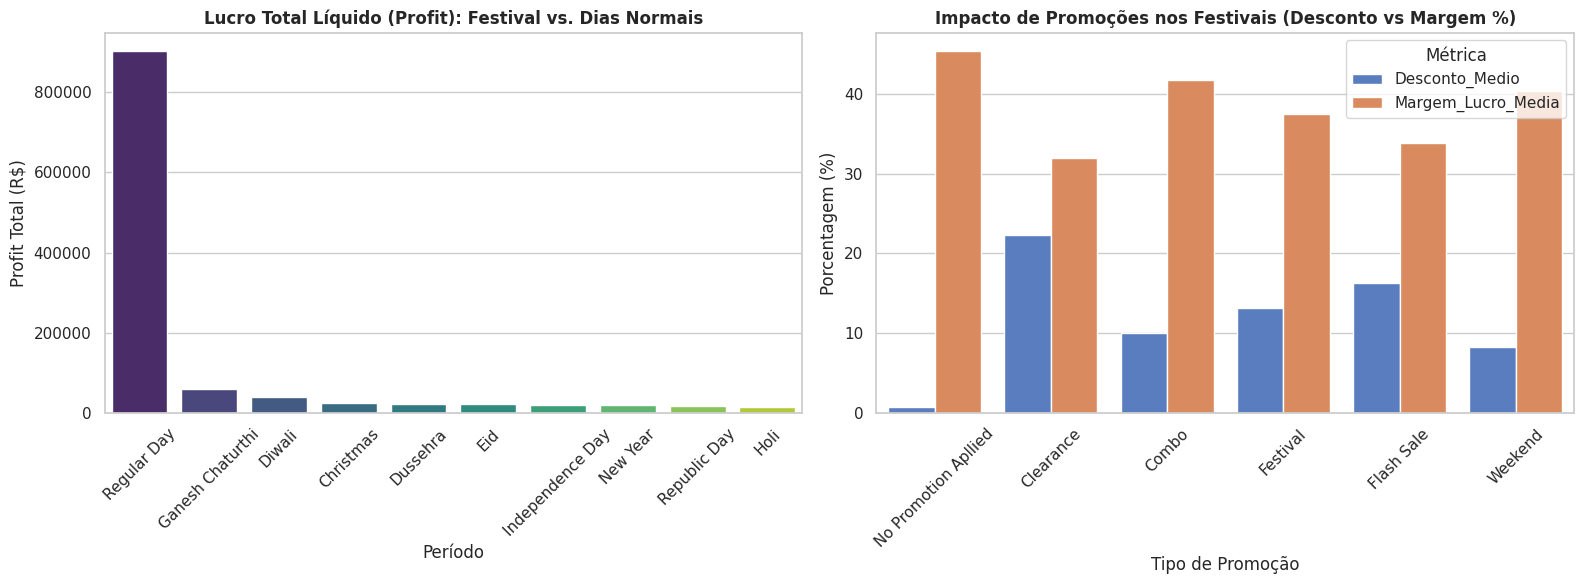

In [ ]:
# ---------------------------------------------------------
# Step 1: Engenharia de Recursos Financeiros
# ---------------------------------------------------------
df["Unsold_Units"] = df["Units_Produced"] - df["Units_Sold"]
df["Waste_Cost_Financial"] = df["Unsold_Units"] * df["Cost_Price"]
df["Profit_Margin_%"] = (df["Profit"] / df["Total_Bill"]) * 100

# ---------------------------------------------------------
# Step 2: Comparativo Consolidado: Festival vs. Dias Normais
# ---------------------------------------------------------
analise_festival = (
    df.groupby("Festival")
    .agg(
        Total_Pedidos=("Order_ID", "count"),
        Volume_Vendido=("Units_Sold", "sum"),
        Volume_Produzido=("Units_Produced", "sum"),
        Faturamento_Total=("Total_Bill", "sum"),
        Profit_Total=("Profit", "sum"),
        Custo_Desperdicio_Total=("Waste_Cost_Financial", "sum"),
        Ticket_Medio=("Total_Bill", "mean"),
        Profit_Medio_Pedido=("Profit", "mean"),
        Desconto_Medio_Pct=("Discount_Percentage", "mean"),
        Margem_Lucro_Media_Pct=("Profit_Margin_%", "mean"),
    )
    .reset_index()
)

analise_festival["Margem_Global_Pct"] = (
    analise_festival["Profit_Total"] / analise_festival["Faturamento_Total"]
) * 100

analise_festival["Waste_Pct_Weighted"] = (
    (analise_festival["Volume_Produzido"] - analise_festival["Volume_Vendido"])
    / analise_festival["Volume_Produzido"]
) * 100

print("=== COMPARATIVO FINANCEIRO: FESTIVAL VS. DIAS NORMAIS ===")
print(analise_festival.to_string(index=False))

# ---------------------------------------------------------
# Step 3: Análise por Tipo de Promoção nos Festivais
# ---------------------------------------------------------
promocoes_festivais = (
    df[df["Festival"] != "Regular Day"]
    .groupby(["Promotion_Applied", "Promotion_Type"], observed=False)
    .agg(
        Total_Pedidos=("Order_ID", "count"),
        Volume_Vendido=("Units_Sold", "sum"),
        Faturamento_Total=("Total_Bill", "sum"),
        Profit_Total=("Profit", "sum"),
        Desconto_Medio=("Discount_Percentage", "mean"),
        Margem_Lucro_Media=("Profit_Margin_%", "mean"),
    )
    .reset_index()
)

print("\n=== DESEMPENHO DE PROMOÇÕES EM DIAS DE FESTIVAL ===")
print(promocoes_festivais.to_string(index=False))

# ---------------------------------------------------------
# Step 4: Visualizações Gráficas
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Lucro Total por Festival
sns.barplot(
    data=analise_festival.sort_values(by="Profit_Total", ascending=False),
    x="Festival",
    y="Profit_Total",
    hue="Festival",
    ax=axes[0],
    palette="viridis",
    legend=False
)
axes[0].set_title("Lucro Total Líquido (Profit): Festival vs. Dias Normais", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Período")
axes[0].set_ylabel("Profit Total (R$)")
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2: Descontos vs Margem de Lucro por Tipo de Promoção em Festivais
df_melted = pd.melt(
    promocoes_festivais,
    id_vars=["Promotion_Type"],
    value_vars=["Desconto_Medio", "Margem_Lucro_Media"],
    var_name="Métrica",
    value_name="Porcentagem"
)

sns.barplot(
    data=df_melted,
    x="Promotion_Type",
    y="Porcentagem",
    hue="Métrica",
    ax=axes[1],
    palette="muted"
)
axes[1].set_title("Impacto de Promoções nos Festivais (Desconto vs Margem %)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tipo de Promoção")
axes[1].set_ylabel("Porcentagem (%)")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()